# Model Selection, Regularisation and Gaussian Processes

A model that reproduces its training data perfectly is usually useless. Given enough parameters, any model can pass through every data point – including the noise. What we really want is a model that **generalises**: that predicts well for new operating points, new parts, next week's data. This chapter introduces the central idea of machine learning: models must be judged on data they have not seen during fitting.

We study how model complexity affects the prediction error, learn to estimate this error honestly with cross-validation, and meet two ways to control complexity: regularisation, which penalises large coefficients, and Gaussian processes, a Bayesian approach that also tells us how uncertain each prediction is.

::: {.scenario}
**Scenario: a surrogate model instead of wind tunnel time**

An aerodynamics team is screening thousands of airfoil configurations for a quiet fan blade. Each wind tunnel measurement costs half a day. The team lead asks whether a data-driven model, trained on the existing NASA measurements, could replace the tunnel for the screening stage. The acoustics expert sets the requirement: the prediction error on *new* conditions must be below 2 dB (RMSE), otherwise the ranking of configurations is unreliable.

**Your decision:** Which model, if any, do you release for the screening?
:::

**Learning goals.** After this chapter you can

- explain overfitting and the bias–variance trade-off,
- evaluate models with train/test splits and k-fold cross-validation,
- build preprocessing and model as a scikit-learn pipeline and avoid data leakage,
- use Ridge and Lasso regression to control model complexity,
- fit Gaussian process regression models and interpret their prediction uncertainty,
- (extension) explain the idea of Bayesian optimisation for expensive experiments.

**Datasets in this chapter**

- [Airfoil Self-Noise (UCI)](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise)
- [Combined Cycle Power Plant (UCI)](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant)

## Training error, test error and overfitting

Suppose the data are generated by $y = f(x) + \varepsilon$ with an unknown function $f$ and noise $\varepsilon$ with variance $\sigma^2$. We fit a model $\hat f$ on a training set. Its error on the **training data** is always optimistic: the model was tuned to exactly these points. The relevant quantity is the expected error on **new data** from the same process – the *generalisation error* or *test error*.

![Under- and overfitting. A model that is too simple (left) misses the structure; a model that is too flexible (centre) follows the noise of the training data. The test error is U-shaped in model complexity (right), while the training error keeps decreasing.](images/overfitting.png){#fig-overfitting width=100%}

::: {.callout-important}
## Bias–variance decomposition
For squared error loss, the expected test error at a point $x$ decomposes into
$$E\big[(y - \hat f(x))^2\big] = \underbrace{\big(E[\hat f(x)] - f(x)\big)^2}_{\text{bias}^2} + \underbrace{\text{Var}\big(\hat f(x)\big)}_{\text{variance}} + \underbrace{\sigma^2}_{\text{irreducible noise}}.$$
Simple models have high **bias** (systematic error, *underfitting*); flexible models have high **variance** (they change strongly with the training sample, *overfitting*). The best model balances both. The noise $\sigma^2$ cannot be reduced by any model.
:::

The practical consequence: **never judge a model by its training error.** Set data aside for testing, or use cross-validation.

## Cross-validation

::: {.callout-note}
## Definition: k-fold cross-validation
Split the data randomly into $k$ parts (*folds*) of equal size. For each fold, train the model on the other $k-1$ folds and compute the error on the held-out fold. The **cross-validation error** is the average over the $k$ folds. Typical values are $k = 5$ or $k = 10$.
:::

![5-fold cross-validation: each observation is used for testing exactly once and for training four times.](images/kfold.png){#fig-kfold width=80%}

Cross-validation uses the data efficiently and gives, besides the mean, an idea of the variability of the error across folds. It is the standard tool to **select** a model or a hyperparameter (polynomial degree, regularisation strength). If the selected model's performance must be reported, use a separate **test set** that was never touched during selection – otherwise the reported error is again optimistic.

::: {.callout-warning}
## Pitfall: data leakage
Any information from the test data that influences training makes the test error too optimistic. Typical leaks: scaling or imputing with statistics of the full dataset, selecting features by their correlation with the target on all data, random splits of time series (Chapter 11), or several rows of the same part/machine in both training and test set. In scikit-learn, putting all preprocessing steps into a `Pipeline` ensures that they are fitted inside each training fold only.
:::

::: {.callout-tip}
## Engineering practice: one median for training and test data
In Chapter 2, the gaps in SECOM were filled with medians. Which median fills the gaps in the *test* data? The **training** median – not one computed from the test data. The median is a parameter of the model, just like a regression coefficient: it is estimated once from the training data and then applied unchanged to all new data. Three reasons:

- In operation there is no "test median": new data often arrive one observation at a time – a single production run, a single sensor reading – and a median cannot be computed from one value.
- The model must always receive the same preprocessing. If a gap was filled with 52.3 during training but with 48.9 during testing, the model sees inputs it was not trained on.
- A test median would itself be a small leak: the prediction for one test point would depend on the other test points.

The same holds for scaling, PCA and every other preprocessing step: `fit` on the training data, `transform` on training *and* test data – exactly what a `Pipeline` does. If the distribution of new data drifts away from the training data, the remedy is to monitor the drift and retrain – not to compute statistics on the test data. (One legitimate exception: if a whole batch – say all wafers of a lot – is always available at prediction time, statistics per batch may be used, but then in exactly the same way during training.)
:::

## Regularisation: Ridge and Lasso

Instead of choosing between few and many features, we can keep a flexible model and penalise large coefficients:

::: {.callout-note}
## Definition: Ridge and Lasso regression
$$\text{Ridge:}\quad \min_\beta \sum_i (y_i - x_i^\top\beta)^2 + \lambda \sum_j \beta_j^2, \qquad \text{Lasso:}\quad \min_\beta \sum_i (y_i - x_i^\top\beta)^2 + \lambda \sum_j |\beta_j|.$$
The hyperparameter $\lambda \ge 0$ (in scikit-learn: `alpha`) controls the strength of the penalty: $\lambda = 0$ gives ordinary least squares, large $\lambda$ shrinks all coefficients towards zero.
:::

Ridge shrinks coefficients smoothly and copes well with collinear inputs. Lasso can set coefficients **exactly to zero** and thus performs feature selection. Because the penalty depends on the size of the coefficients, the inputs must be **standardised** first – otherwise the penalty depends on the units. $\lambda$ is chosen by cross-validation (`RidgeCV`, `LassoCV`).

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Live coding: airfoil self-noise

NASA measured the self-noise of airfoil sections (NACA 0012 profiles of different chord lengths) in an anechoic wind tunnel. The noise is generated by the interaction of the turbulent boundary layer with the trailing edge – a physically complex mechanism that is hard to model from first principles. The dataset has 1,503 measurements:

| Input | Meaning | Unit |
| --- | --- | --- |
| `frequency` | frequency | Hz |
| `angle` | angle of attack | deg |
| `chord` | chord length | m |
| `velocity` | free-stream velocity | m/s |
| `thickness` | suction side displacement thickness | m |
| **`spl`** (target) | scaled sound pressure level | dB |

In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

air = fetch_ucirepo(id=291)
X = air.data.features.copy()
X.columns = ["frequency", "angle", "chord", "velocity", "thickness"]   # Hz, deg, m, m/s, m
y = air.data.targets.iloc[:, 0].rename("spl")                           # dB
X.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
frequency,1503.0,2886.3806,3152.5731,200.0000,800.0000,1600.0000,4000.0000,20000.0000
angle,1503.0,6.7823,5.9181,0.0000,2.0000,5.4000,9.9000,22.2000
chord,1503.0,0.1365,0.0935,0.0254,0.0508,0.1016,0.2286,0.3048
velocity,1503.0,50.8607,15.5728,31.7000,39.6000,39.6000,71.3000,71.3000
thickness,1503.0,0.0111,0.0132,0.0004,0.0025,0.0050,0.0156,0.0584


### How complex should the model be?

We fit polynomial models of increasing degree – with five inputs, degree 6 already produces several hundred terms – and compare training and cross-validation errors.

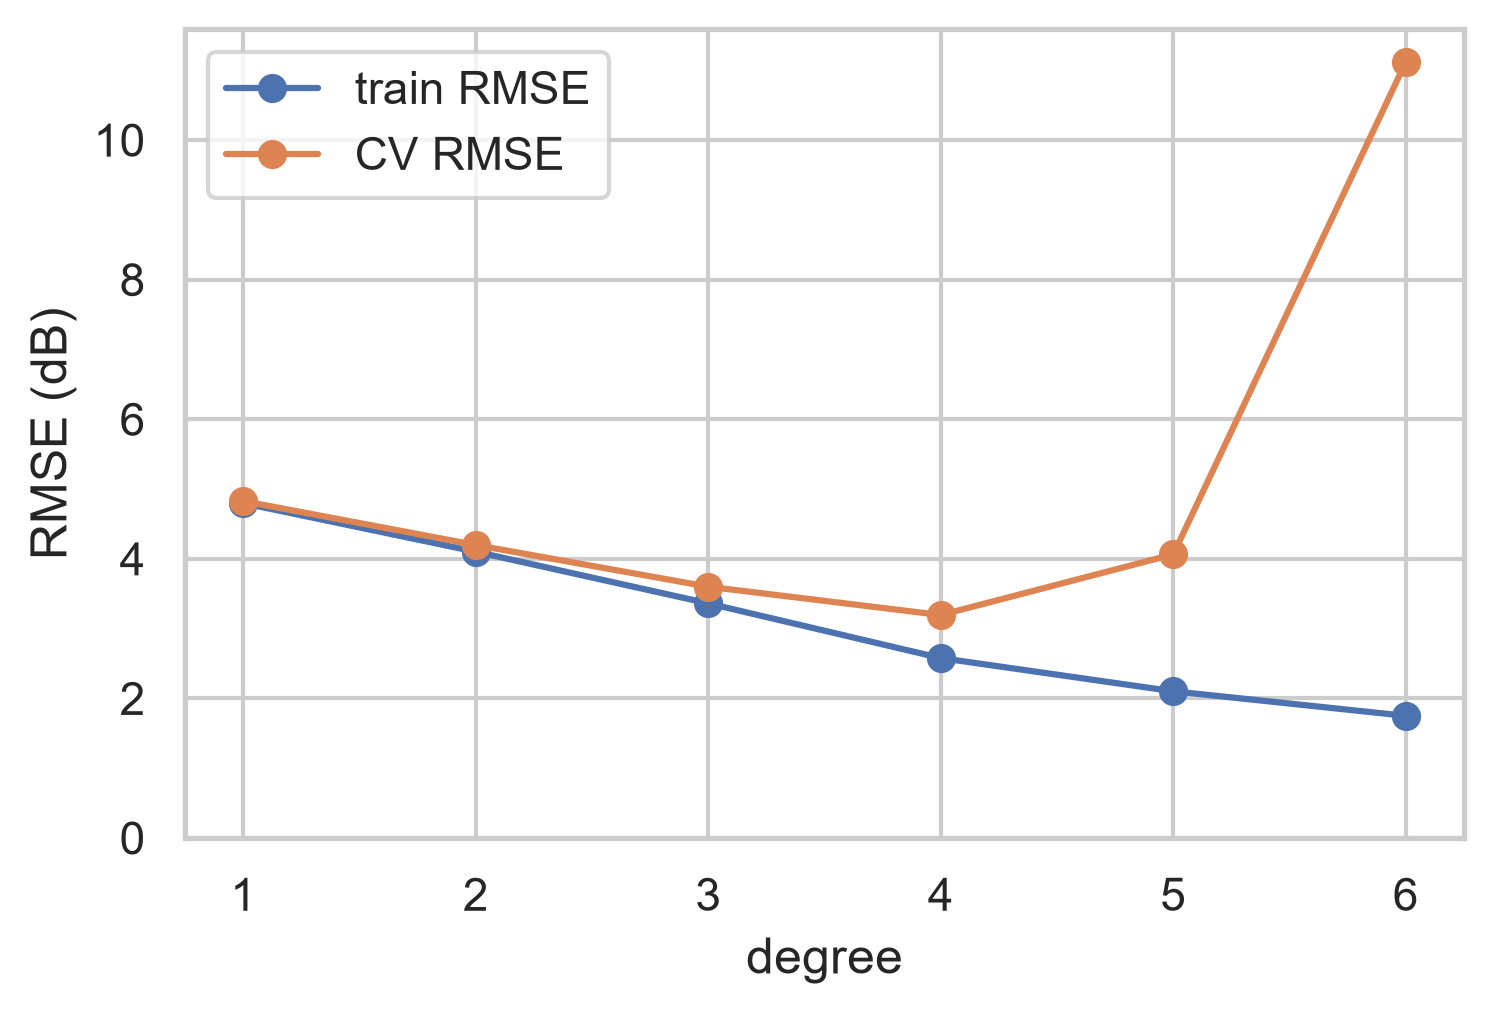

,terms,train RMSE,CV RMSE
degree,,,
1,6,4.80,4.83
2,21,4.10,4.20
3,56,3.36,3.60
4,126,2.58,3.19
5,252,2.10,4.06
6,462,1.75,11.12


In [3]:
#| code-fold: false
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for degree in range(1, 7):
    pipe = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    res = cross_validate(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error",
                         return_train_score=True)
    rows.append({"degree": degree, "terms": PolynomialFeatures(degree).fit(X).n_output_features_,
                 "train RMSE": -res["train_score"].mean(), "CV RMSE": -res["test_score"].mean()})
scores = pd.DataFrame(rows).set_index("degree")
ax = scores[["train RMSE", "CV RMSE"]].plot(marker="o")
ax.set(ylabel="RMSE (dB)", ylim=(0, None))
plt.show()
scores.round(2)

**Discussion.** The training error decreases steadily with the degree – more terms can always fit the training data better. The cross-validation error first decreases (less bias) and eventually increases again (more variance); its minimum indicates a good degree. The growing gap between training and CV error is the signature of overfitting. Note also the scale: a straight-line model leaves errors of several dB, which matters for acoustic requirements.

### Regularisation in action

Instead of picking the degree exactly, we can use a rich model and let Ridge regression control its complexity. `RidgeCV` selects $\lambda$ by internal cross-validation; the outer cross-validation evaluates the whole procedure.

In [4]:
#| code-fold: false
ridge = make_pipeline(PolynomialFeatures(5), StandardScaler(),
                      RidgeCV(alphas=np.logspace(-4, 3, 30)))
res_ridge = cross_validate(ridge, X, y, cv=cv, scoring="neg_root_mean_squared_error")
print(f"Ridge, degree 5: CV RMSE = {-res_ridge['test_score'].mean():.2f} dB")

Ridge, degree 5: CV RMSE = 3.14 dB


::: {.callout-tip}
## Engineering practice: nested model selection
Here, cross-validation happens at two levels: `RidgeCV` chooses $\lambda$ on the training part of each outer fold, and the outer loop measures how well the *whole procedure* (including the choice of $\lambda$) generalises. This **nested cross-validation** gives an honest estimate. Choosing $\lambda$ on the same folds used to report the error would again be optimistic.
:::

## Gaussian process regression: predictions with uncertainty

Polynomial and linear models assume a fixed functional form. A **Gaussian process (GP)** places a probability distribution directly over functions – it is the Bayesian approach to regression.

::: {.callout-note}
## Definition: Gaussian process
A Gaussian process is a collection of random variables $f(x)$, any finite number of which have a joint normal distribution. It is specified by a mean function (often 0) and a **kernel** (covariance function) $\kappa(x, x')$ that states how strongly the function values at $x$ and $x'$ are correlated. A common choice is the squared exponential (RBF) kernel
$$\kappa(x, x') = \sigma_f^2 \exp\left(-\frac{\|x - x'\|^2}{2\ell^2}\right),$$
with signal variance $\sigma_f^2$ and **length scale** $\ell$ (we write $\kappa$ to avoid confusion with the $k$ of k-fold cross-validation): points closer than about $\ell$ have similar function values.
:::

Given training data, the GP posterior at a new point is again normal: its **mean** is the prediction and its **standard deviation** quantifies the uncertainty. Near the training points the uncertainty is small, far away it grows back to the prior level. The kernel hyperparameters and the noise level are fitted by maximising the marginal likelihood – no cross-validation needed.

![A Gaussian process before and after observing data. Left: functions drawn from the prior. Right: after five noisy observations, the posterior mean interpolates the data and the uncertainty band is narrow near the observations and wide in between and outside.](images/gp-prior-posterior.png){#fig-gp width=100%}

GPs are popular as **surrogate models** for expensive simulations and experiments, where data are scarce and knowing the uncertainty matters. Their limitation: the computational cost grows with $n^3$, so they suit datasets up to a few thousand points.

We first look at a one-dimensional example: the power output of the combined cycle power plant as a function of ambient temperature, learned from only 15 measurements.

Fitted kernel: 2.27**2 * RBF(length_scale=29.5) + WhiteKernel(noise_level=0.118)


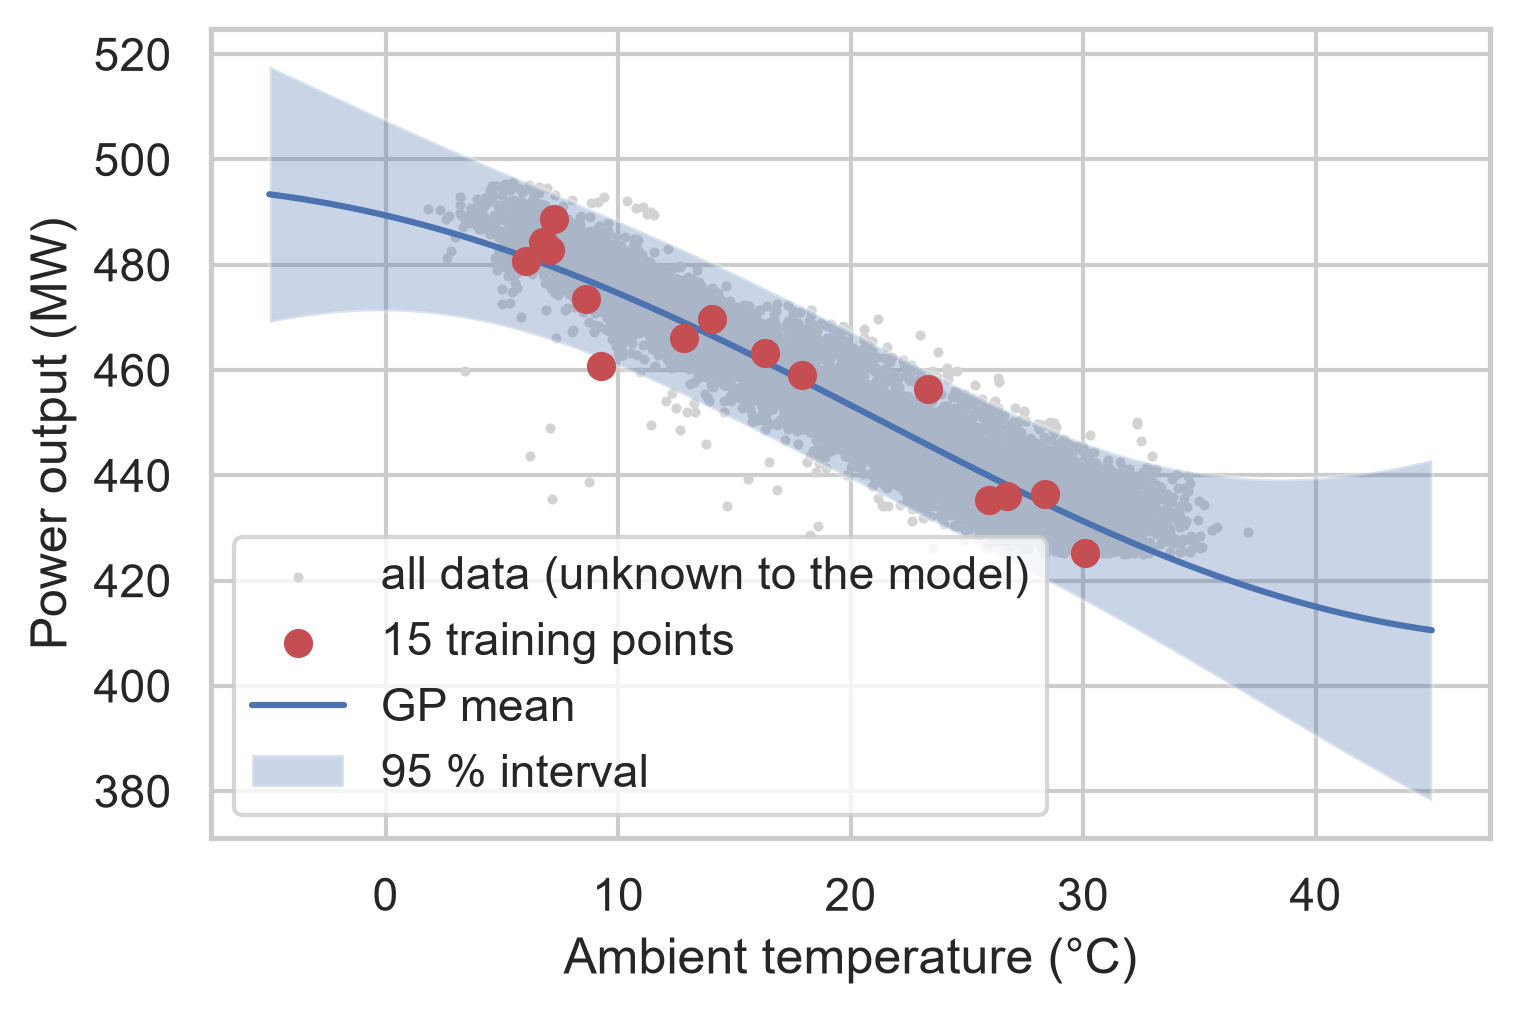

In [5]:
#| code-fold: false
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C

ccpp = fetch_ucirepo(id=294)
pp = pd.concat([ccpp.data.features, ccpp.data.targets], axis=1)
few = pp.sample(15, random_state=1)

kernel = C(100.0) * RBF(length_scale=10.0) + WhiteKernel(noise_level=10.0)
gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=0)
gp.fit(few[["AT"]], few["PE"])
print("Fitted kernel:", gp.kernel_)

T = np.linspace(-5, 45, 300).reshape(-1, 1)
mean, std = gp.predict(pd.DataFrame(T, columns=["AT"]), return_std=True)
plt.scatter(pp["AT"], pp["PE"], s=2, c="lightgray", label="all data (unknown to the model)")
plt.scatter(few["AT"], few["PE"], c="C3", zorder=3, label="15 training points")
plt.plot(T, mean, label="GP mean")
plt.fill_between(T.ravel(), mean - 1.96 * std, mean + 1.96 * std, alpha=0.3, label="95 % interval")
plt.xlabel("Ambient temperature (°C)"); plt.ylabel("Power output (MW)"); plt.legend()
plt.show()

**Discussion.** With only 15 points, the GP recovers the almost linear trend. The fitted `WhiteKernel` noise level estimates the scatter of the individual measurements, the RBF length scale how quickly the function can change. Outside the measured temperature range (below the coldest and above the warmest training point), the band widens: the model honestly reports that it does not know. A polynomial would extrapolate with the same confidence everywhere.

In [6]:
#| code-fold: false
# GP on the full airfoil problem (5 inputs), compared with the polynomial ridge model
gp_air = make_pipeline(StandardScaler(), GaussianProcessRegressor(
    kernel=C(1.0) * RBF(length_scale=np.ones(5)) + WhiteKernel(0.1), normalize_y=True))
res_gp = cross_validate(gp_air, X, y, cv=cv, scoring="neg_root_mean_squared_error")
print(f"Gaussian process: CV RMSE = {-res_gp['test_score'].mean():.2f} dB")

Gaussian process: CV RMSE = 1.89 dB


Here we use one length scale per input (an *anisotropic* or ARD kernel). After fitting, a long length scale indicates that the output changes slowly with that input – a built-in measure of relevance.

## Back to the decision

The requirement refers to new conditions, so we compare the cross-validation errors – never the training errors. Among the models that meet the 2 dB requirement, we release the simplest one; if none meets it, the tunnel cannot yet be replaced.

In [7]:
#| code-fold: false
cv_rmse = {
    "linear model": scores.loc[1, "CV RMSE"],
    f"polynomial (degree {scores['CV RMSE'].idxmin()})": scores["CV RMSE"].min(),
    "polynomial degree 5 + Ridge": -res_ridge["test_score"].mean(),
    "Gaussian process": -res_gp["test_score"].mean(),
}
for name, e in cv_rmse.items():
    print(f"{name:32s} CV RMSE = {e:.2f} dB {'✓' if e < 2.0 else '✗'}")
ok = [name for name, e in cv_rmse.items() if e < 2.0]
print("Decision:", f"release '{ok[0]}' for the screening." if ok else "no model is accurate enough – keep using the tunnel.")

linear model                     CV RMSE = 4.83 dB ✗
polynomial (degree 4)            CV RMSE = 3.19 dB ✗
polynomial degree 5 + Ridge      CV RMSE = 3.14 dB ✗
Gaussian process                 CV RMSE = 1.89 dB ✓
Decision: release 'Gaussian process' for the screening.


The models are listed from simple to complex, so the first model that meets the requirement is released. Two caveats belong in the recommendation: cross-validation estimates the error for conditions *similar* to the measured ones – for configurations outside the measured ranges (e.g. larger chords or higher speeds) the error can be much larger, and the Gaussian process at least signals this through its uncertainty. And the best candidates of the screening should still be confirmed in the tunnel.

## Extension: Bayesian optimisation – design of experiments with a GP

*Extension – optional material, not required for the exam.*

When every experiment is expensive – a test bench run, a CFD simulation, a production trial – we want to find the optimum with as few runs as possible. **Bayesian optimisation** fits a GP to the runs so far and chooses the next run where an *acquisition function* is largest. The popular **expected improvement** (EI) is

$$\text{EI}(x) = (\mu(x) - y^*)\,\Phi(z) + \sigma(x)\,\varphi(z), \qquad z = \frac{\mu(x) - y^*}{\sigma(x)},$$

where $\mu(x)$ and $\sigma(x)$ are the GP's predicted mean and standard deviation at $x$, $y^*$ is the best result so far and $\Phi, \varphi$ are the standard normal CDF and PDF. EI is large where the predicted mean is high (*exploitation*) or the uncertainty is large (*exploration*).

The example uses a simulated "experiment": the yield of a process as a function of temperature, which the algorithm does not know.

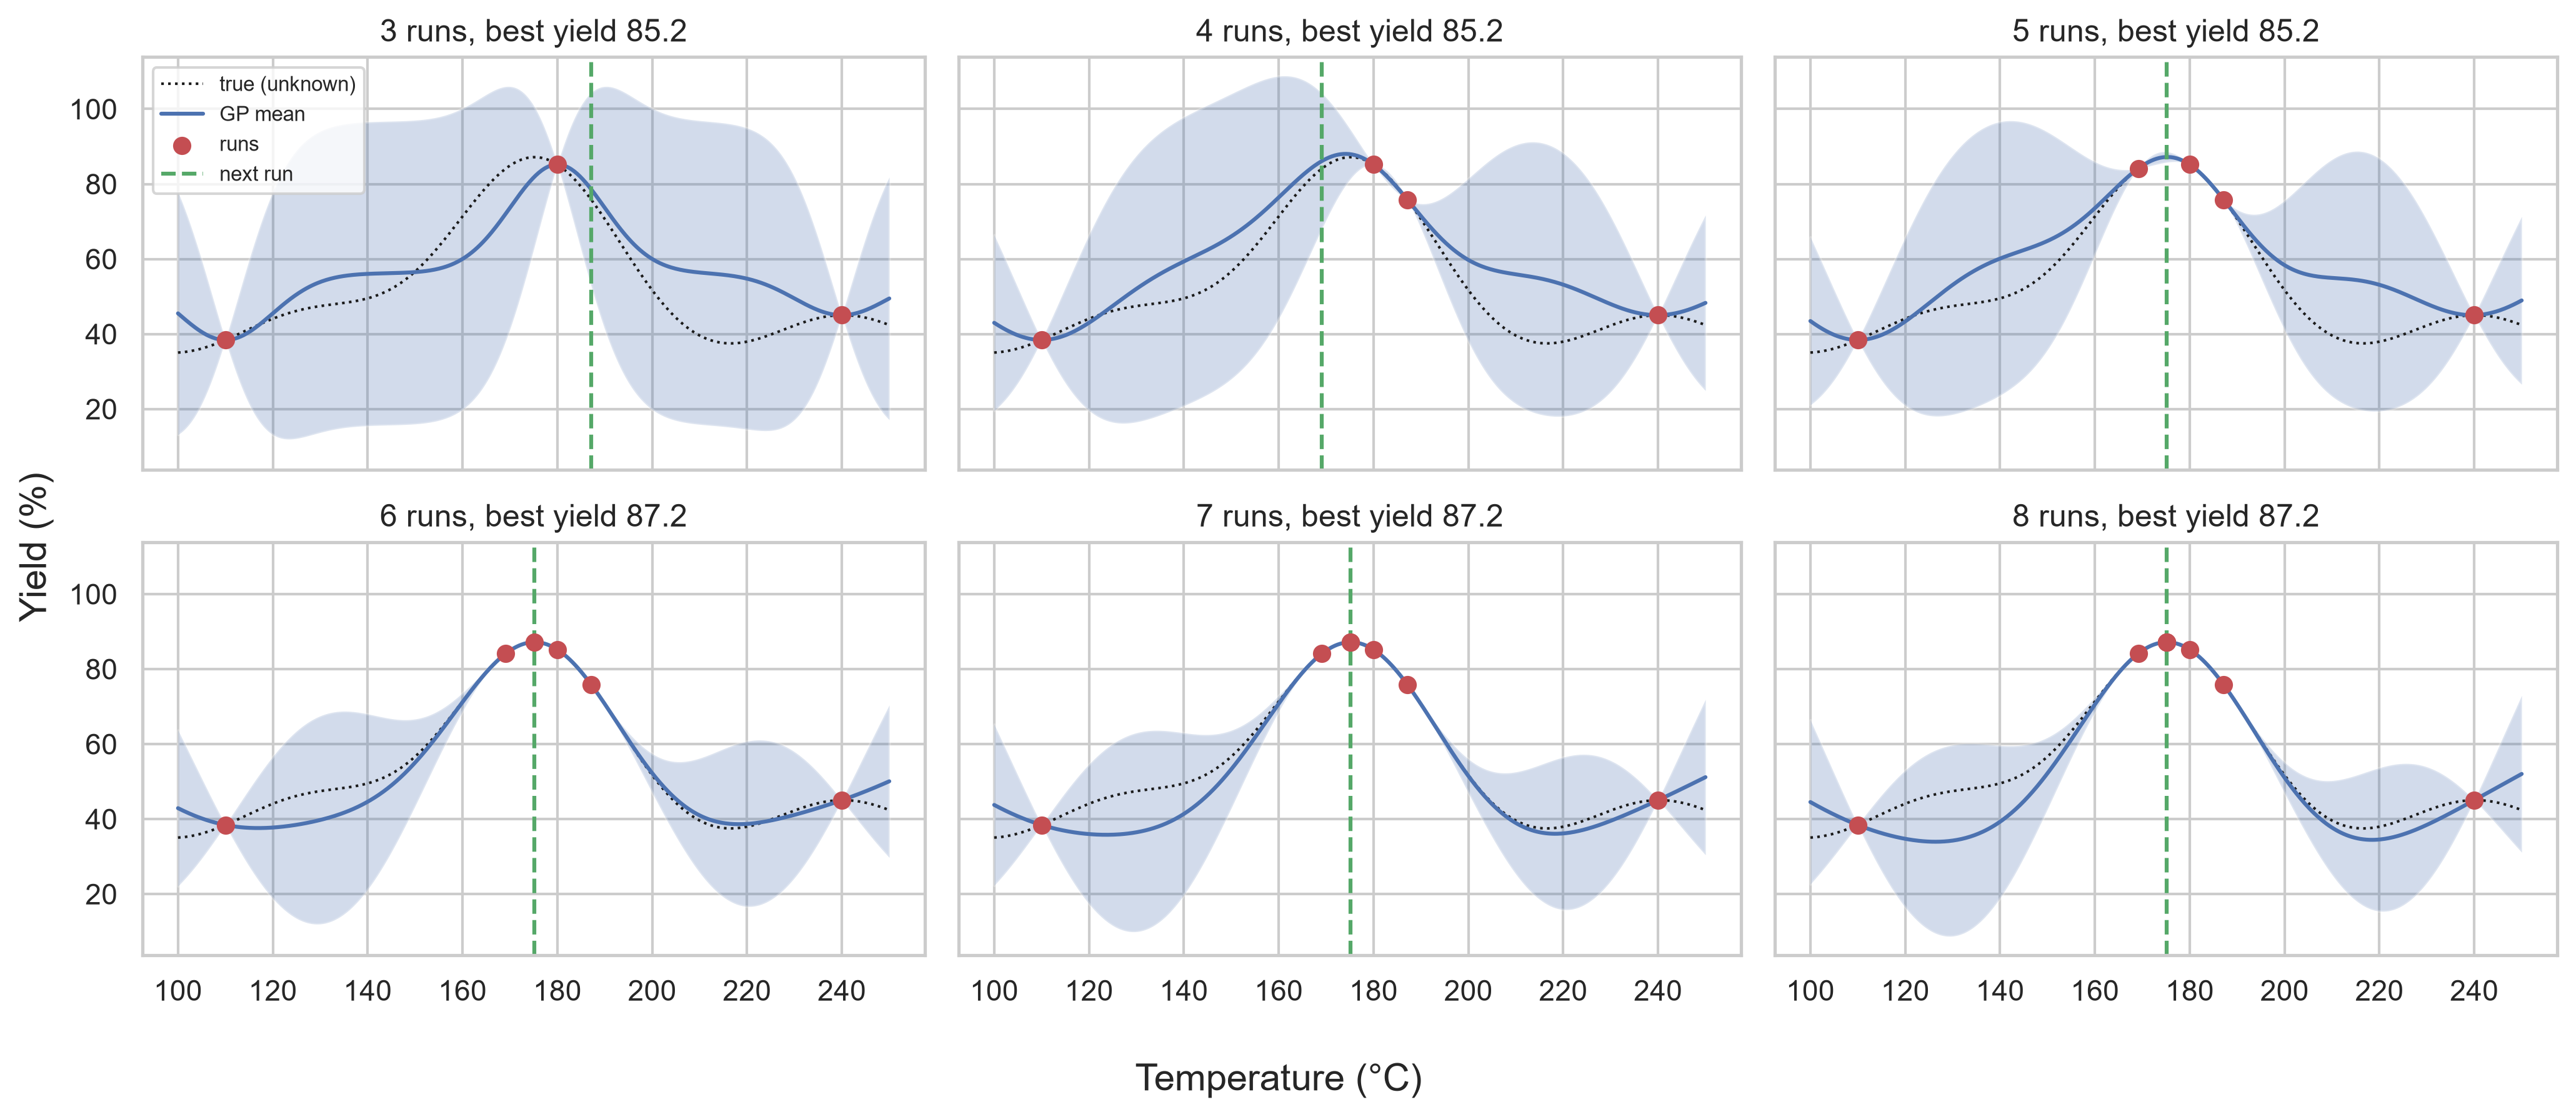

In [8]:
#| code-fold: false
from scipy.stats import norm

def experiment(temp):                       # unknown to the optimiser
    return 40 + 45 * np.exp(-((temp - 172) / 25) ** 2) + 5 * np.sin(temp / 9)

grid = np.linspace(100, 250, 500).reshape(-1, 1)
X_runs = np.array([[110.0], [180.0], [240.0]])            # three initial runs
y_runs = experiment(X_runs.ravel())

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax in axes.ravel():
    gp_bo = GaussianProcessRegressor(C(1.0) * RBF(20.0), normalize_y=True, alpha=1e-6)
    gp_bo.fit(X_runs, y_runs)
    mu, sd = gp_bo.predict(grid, return_std=True)
    best = y_runs.max()
    z = (mu - best) / np.maximum(sd, 1e-9)
    ei = (mu - best) * norm.cdf(z) + sd * norm.pdf(z)       # expected improvement
    x_next = grid[np.argmax(ei)]

    ax.plot(grid, experiment(grid.ravel()), "k:", lw=1, label="true (unknown)")
    ax.plot(grid, mu, label="GP mean")
    ax.fill_between(grid.ravel(), mu - 1.96 * sd, mu + 1.96 * sd, alpha=0.25)
    ax.scatter(X_runs, y_runs, c="C3", zorder=3, label="runs")
    ax.axvline(x_next[0], c="C2", ls="--", label="next run")
    ax.set_title(f"{len(y_runs)} runs, best yield {best:.1f}")

    X_runs = np.vstack([X_runs, x_next])
    y_runs = np.append(y_runs, experiment(x_next[0]))
axes[0, 0].legend(fontsize=8)
fig.supxlabel("Temperature (°C)"); fig.supylabel("Yield (%)")
plt.tight_layout(); plt.show()

**Discussion.** After a few iterations the algorithm concentrates its runs near the optimum, while regions that cannot contain a better result are not explored further. Compared with a classical grid (Chapter 5), Bayesian optimisation adapts the design sequentially to the results – very efficient when runs are expensive and can be done one after another. Once the optimum is found, EI becomes small everywhere and the proposals cluster; in practice one stops when the expected improvement falls below a threshold.

::: {.callout-important}
## Key takeaways
- The training error is optimistic; judge models by their error on unseen data.
- The test error is U-shaped in model complexity: too simple → bias, too flexible → variance.
- k-fold cross-validation selects models and hyperparameters; preprocessing belongs inside the pipeline.
- Ridge and Lasso control complexity by penalising coefficients (standardise first!).
- Gaussian processes give predictions with uncertainty – valuable for small data and expensive experiments.
:::

## Exercises

<div class="exercises">

1. Repeat the degree study for the power plant data (`pp`, target `PE`). Why does the curve look so different from the airfoil case?
2. Why must the `StandardScaler` be part of the pipeline instead of being fitted on all data beforehand? Construct an example in which the difference becomes visible.
3. Plot predicted vs. measured sound pressure level for the Ridge model, using `cross_val_predict`. In which range does the model fail?
4. GP: increase the number of training points from 15 to 50 and 200. How does the uncertainty band change? What happens outside the measured temperature range?
5. (Extension) Replace Ridge by `LassoCV` (degree 3). How many of the polynomial features survive?
6. (Extension) Bayesian optimisation: start with a different set of three runs. Does the algorithm still find the optimum? Compare with a regular grid of the same number of runs.

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [9]:
#| code-fold: false
X_pp, y_pp = pp[["AT", "V", "AP", "RH"]], pp["PE"]
rows = []
for degree in range(1, 6):
    pipe = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    res = cross_validate(pipe, X_pp, y_pp, cv=cv, scoring="neg_root_mean_squared_error",
                         return_train_score=True)
    rows.append({"degree": degree, "train RMSE": -res["train_score"].mean(),
                 "CV RMSE": -res["test_score"].mean()})
pd.DataFrame(rows).set_index("degree").round(3)

,train RMSE,CV RMSE
degree,,
1,4.557,4.559
2,4.254,4.260
3,4.149,4.162
4,4.088,4.118
5,4.030,4.073


The power plant relationship is nearly linear, there are only four inputs and almost 10,000 observations. Higher degrees improve the fit only slightly, and training and CV errors stay close together – with this much data relative to the number of parameters, overfitting hardly occurs. The remaining error is dominated by the irreducible noise. The airfoil problem is more nonlinear and has six times less data, so flexibility helps first and then overfits.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2
Fitting the scaler on all data uses the means and standard deviations of the test folds – a (here mild) form of leakage. The effect is small for scaling with many observations but becomes large for steps that use the target, e.g. selecting the features most correlated with $y$ before cross-validation:

In [10]:
#| code-fold: false
from sklearn.feature_selection import SelectKBest, f_regression

rng = np.random.default_rng(0)
noise = pd.DataFrame(rng.normal(size=(100, 2000)))          # pure noise features
target = pd.Series(rng.normal(size=100))                     # unrelated target

leaky_X = SelectKBest(f_regression, k=20).fit_transform(noise, target)   # selection on ALL data
leaky = cross_validate(LinearRegression(), leaky_X, target, cv=cv, scoring="r2")["test_score"].mean()
proper = cross_validate(make_pipeline(SelectKBest(f_regression, k=20), LinearRegression()),
                        noise, target, cv=cv, scoring="r2")["test_score"].mean()
print(f"CV R² with leaky selection: {leaky:.2f},  inside the pipeline: {proper:.2f}")

CV R² with leaky selection: 0.47,  inside the pipeline: -0.32


With selection outside the pipeline, the "model" appears to predict pure noise; inside the pipeline the CV R² is correctly around zero or negative.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

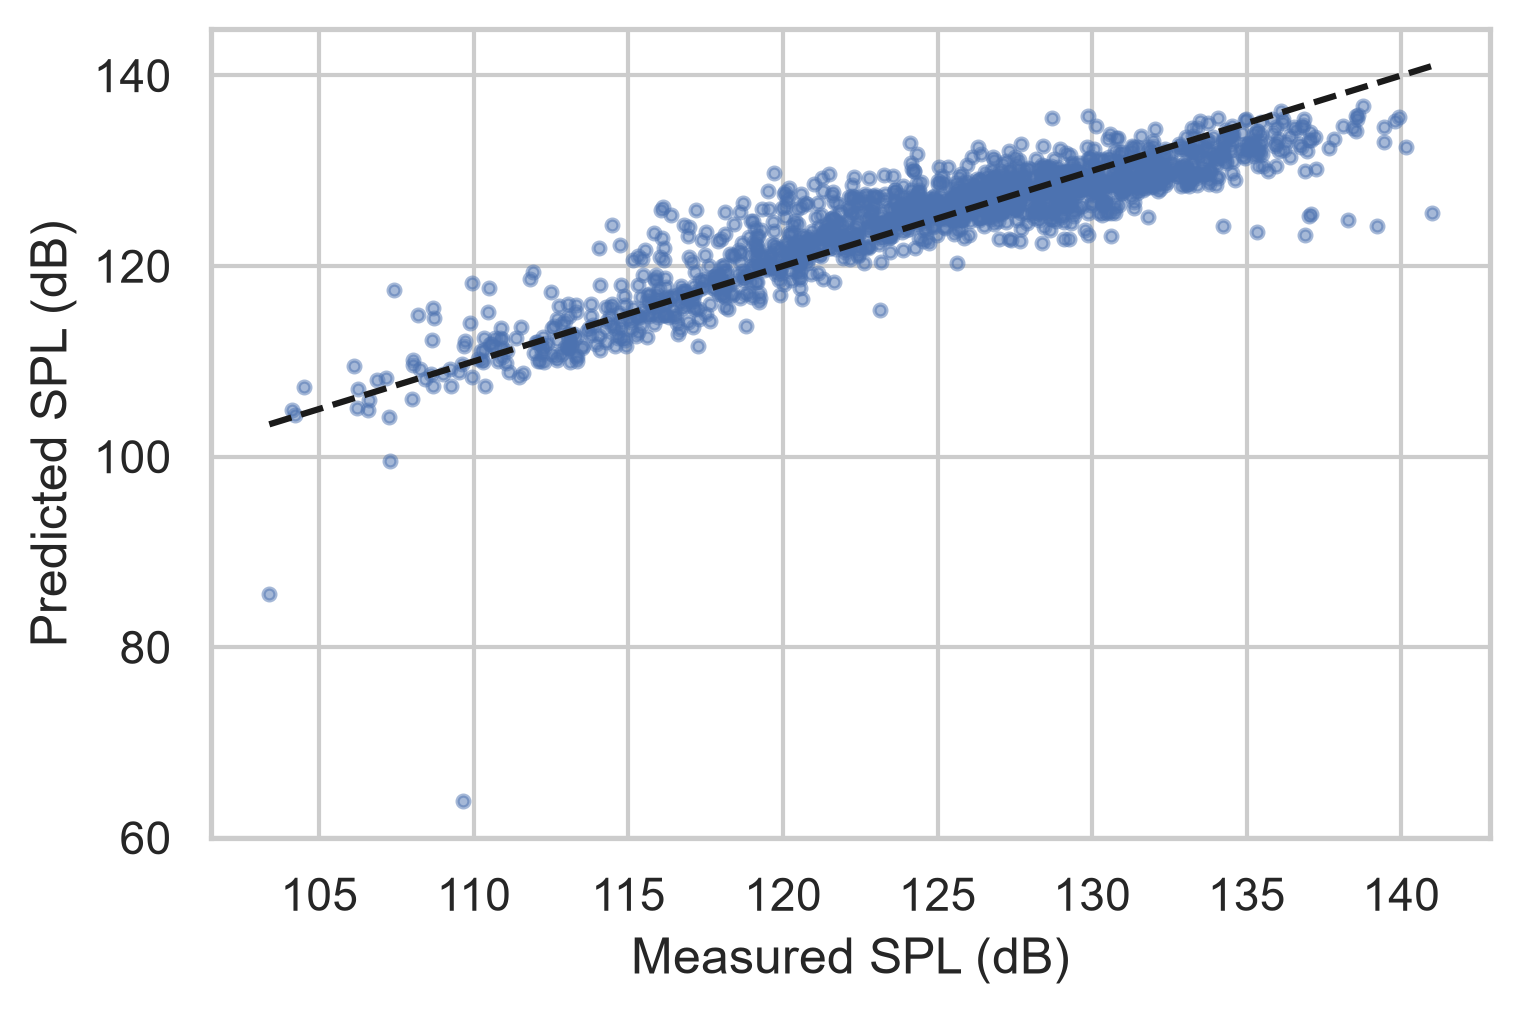

In [11]:
#| code-fold: false
from sklearn.model_selection import cross_val_predict

y_hat = cross_val_predict(ridge, X, y, cv=cv)
plt.scatter(y, y_hat, s=8, alpha=0.5)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "k--")
plt.xlabel("Measured SPL (dB)"); plt.ylabel("Predicted SPL (dB)")
plt.show()

`cross_val_predict` returns for each observation the prediction of the model that did *not* see it during training. Deviations are typically largest at the extremes – the quietest and loudest conditions are underrepresented, and the model shrinks predictions towards the mean (a typical effect of regularisation). Plotting the residuals against frequency shows that some frequency ranges are captured less well than others.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

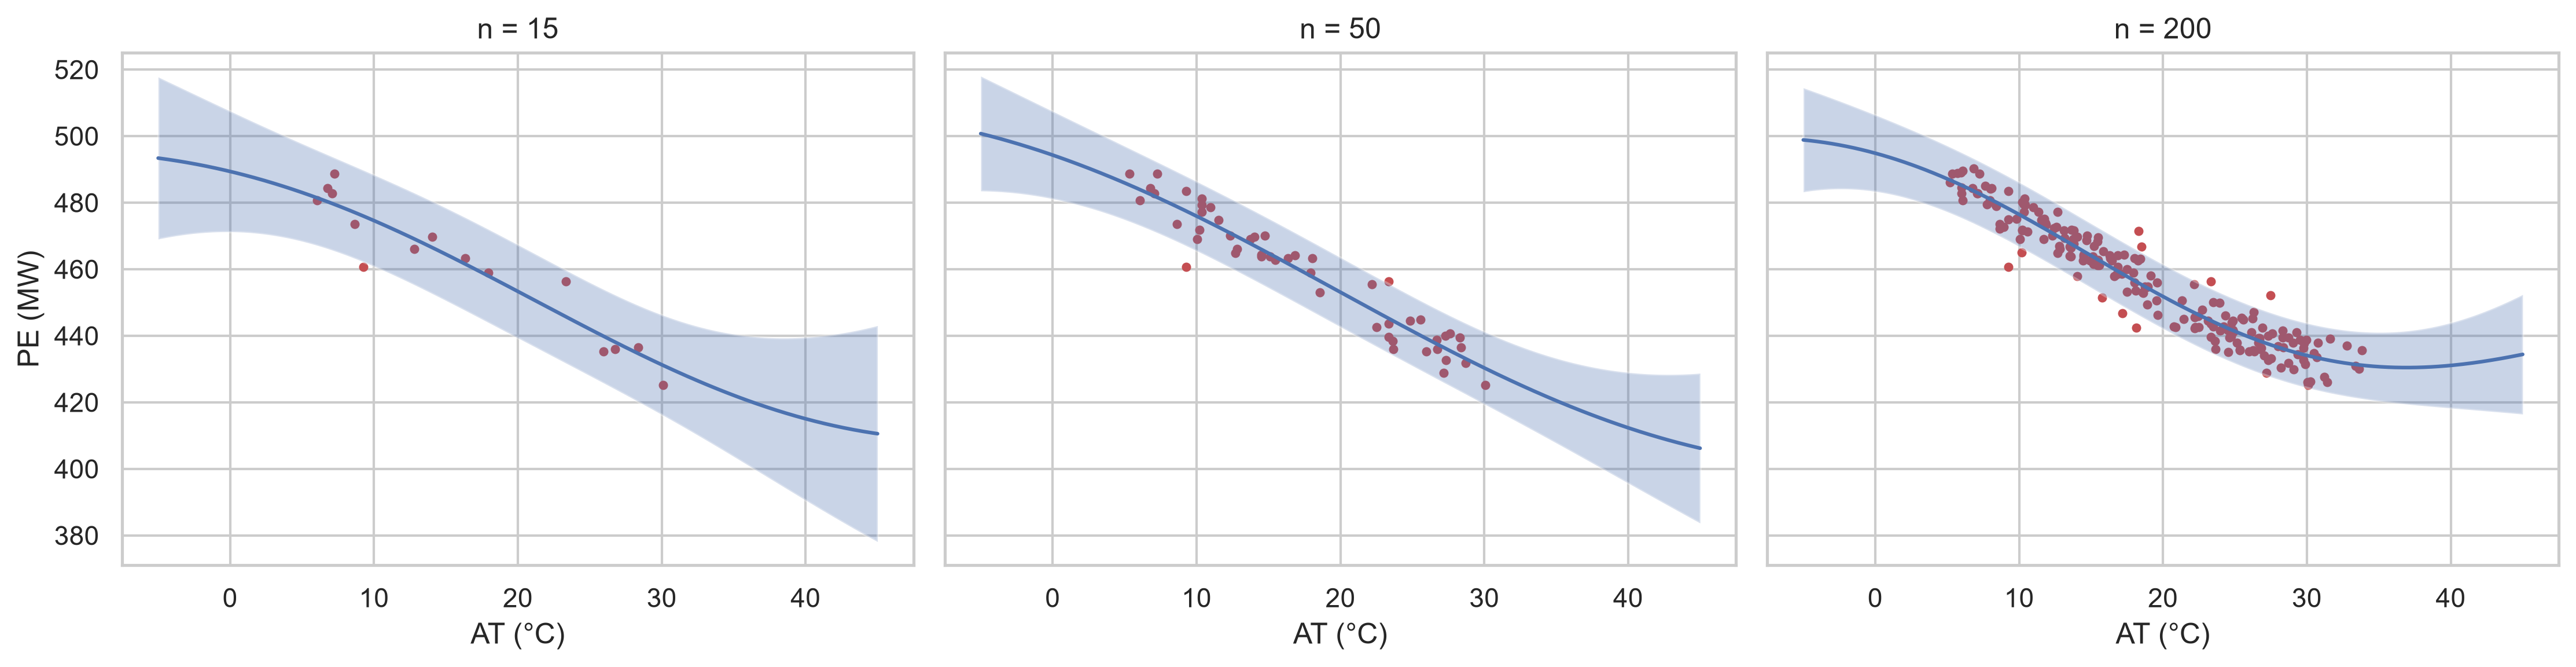

In [12]:
#| code-fold: false
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n_train in zip(axes, [15, 50, 200]):
    sub = pp.sample(n_train, random_state=1)
    g = GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=0).fit(sub[["AT"]], sub["PE"])
    m, s = g.predict(pd.DataFrame(T, columns=["AT"]), return_std=True)
    ax.scatter(sub["AT"], sub["PE"], s=8, c="C3")
    ax.plot(T, m); ax.fill_between(T.ravel(), m - 1.96 * s, m + 1.96 * s, alpha=0.3)
    ax.set(title=f"n = {n_train}", xlabel="AT (°C)")
axes[0].set_ylabel("PE (MW)")
plt.tight_layout(); plt.show()

With more data the band becomes narrower, but it does not shrink to zero: because the kernel contains a `WhiteKernel`, the predicted standard deviation includes the measurement noise, so the band approaches the scatter of individual observations (similar to a prediction interval). The uncertainty about the *trend* itself, however, decreases. Outside the data range the band still widens; with more points the trend is better determined, so the widening is less dramatic. Where there are no data at all, data elsewhere can only reduce the uncertainty as far as the kernel assumes smoothness.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5

In [13]:
#| code-fold: false
from sklearn.linear_model import LassoCV

lasso = make_pipeline(PolynomialFeatures(3), StandardScaler(),
                      LassoCV(cv=5, random_state=0, max_iter=50000)).fit(X, y)
coefs = lasso[-1].coef_
names = lasso[0].get_feature_names_out(X.columns)
print(f"{(coefs != 0).sum()} of {len(coefs)} features survive")
pd.Series(coefs, index=names)[coefs != 0].sort_values(key=abs, ascending=False).head(10).round(3)

22 of 56 features survive


frequency chord         -5.804
frequency thickness     -4.006
frequency^2 chord        1.969
frequency angle chord   -1.947
angle                   -1.946
angle chord velocity     1.935
frequency chord^2        1.800
chord                   -1.715
frequency thickness^2    1.547
frequency^2             -1.390
dtype: float64

Lasso keeps only part of the polynomial terms. The surviving terms show which inputs and interactions matter most; frequency usually dominates, since the noise spectrum depends strongly on it. Note that with correlated features Lasso picks one of a group somewhat arbitrarily – the selection is not a proof of physical relevance.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 6
Change `X_runs` to, e.g., `[[100.0], [130.0], [250.0]]` and rerun the loop. Usually the algorithm still finds the region of the optimum, because the large uncertainty in unexplored regions makes EI large there. With an unlucky start and a misleading local maximum (the sine term), it may need more iterations. A regular grid of 8 runs over 100–250 °C has a spacing of about 21 °C; the best grid point can easily be several percent below the true optimum, and the grid cannot refine itself. Bayesian optimisation pays off when each run is expensive and runs can be performed one after another.
:::